# Notebook 1 — EDA

## Audio-Based Network Intrusion Detection System

This notebook performs comprehensive EDA on **NSL-KDD** and **CICIDS2017** datasets.

### Objectives
- Class and attack distribution analysis
- Correlation heatmaps and feature importance
- Missing values and outlier detection
- Dimensionality reduction visualizations (PCA, t-SNE, UMAP)
- Dimensionality reduction visualizations (PCA, t-SNE, UMAP)


In [1]:
import sys
sys.path.insert(0, '../src')

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from plotly.subplots import make_subplots

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("umap-learn not installed — UMAP plots will be skipped")

from preprocessing import DataLoader, FeatureProcessor

# Publication style
plt.style.use('seaborn-v0_8-whitegrid')
FIG_DIR = '../reports/figures'
import os; os.makedirs(FIG_DIR, exist_ok=True)

SAMPLE_SIZE = 5000  # Adjust for full dataset
RANDOM_STATE = 42


## 1. Data Loading

We load both NSL-KDD (classic benchmark) and CICIDS2017 (modern IDS dataset).
If datasets are not present locally, synthetic samples are generated for reproducible demos.


In [2]:
loader = DataLoader(data_dir='../data/raw')

# NSL-KDD
train_df, test_df = loader.load_nsl_kdd(sample_size=SAMPLE_SIZE)
print(f"NSL-KDD Train: {train_df.shape}")
print(f"NSL-KDD Test:  {test_df.shape if test_df is not None else 'N/A'}")
train_df.head()


NSL-KDD Train: (5000, 45)
NSL-KDD Test:  (5000, 45)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,attack_category,is_attack
378,0,udp,domain_u,SF,36,0,0,0,0,0,...,1.00,0.01,0.00,0.0,0.00,0.0,normal,21,normal,0
32038,0,tcp,http,S0,0,0,0,0,0,0,...,0.01,0.00,1.00,1.0,0.00,0.0,neptune,18,dos,1
86399,0,tcp,pop_3,S0,0,0,0,0,0,0,...,0.00,0.00,1.00,1.0,0.00,0.0,neptune,21,dos,1
74412,0,tcp,private,REJ,0,0,0,0,0,0,...,0.00,0.00,0.00,0.0,1.00,1.0,neptune,19,dos,1
52951,0,tcp,private,RSTR,0,0,0,0,0,0,...,0.64,0.00,0.04,0.0,0.63,1.0,portsweep,15,probe,1


In [3]:
# CICIDS2017
cicids_df = loader.load_cicids2017(sample_size=SAMPLE_SIZE)
print(f"CICIDS2017: {cicids_df.shape}")
cicids_df.head()


CICIDS2017 not found. Generating synthetic sample.


CICIDS2017: (5000, 23)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Flow IAT Mean,Flow IAT Std,Fwd IAT Total,Bwd IAT Total,SYN Flag Count,ACK Flag Count,Down/Up Ratio,label,attack_category,is_attack
0,22197,1148.248764,13,11,27.121863,1.067474,27.798462,14.693561,16.068171,1.680928,...,54.020180,11.732290,51.783728,17.257684,32,0,1.795244,PortScan,port_scan,1
1,14297,544.954726,11,3,35.323767,232.144903,4.025242,8.832586,57.999358,26.721357,...,13.863112,117.123899,217.616594,34.128932,0,2,1.023664,BENIGN,normal,0
2,34100,397.499337,9,10,54.224852,97.851685,35.292159,0.230865,37.358910,23.184061,...,104.555813,3.612333,67.393632,6.947368,15,1,1.546553,FTP-Patator,brute_force,1
3,43445,1078.721010,13,4,170.747154,161.443261,8.254351,6.603331,91.889724,29.873277,...,62.201473,73.265998,134.893609,226.174640,38,3,1.300018,PortScan,port_scan,1
4,17133,2089.148980,10,8,529.347376,157.198847,86.656162,2.138005,63.379909,7.015167,...,25.883561,16.953542,124.508514,283.671284,0,1,0.797537,BENIGN,normal,0


## 2. Class Distribution

Understanding the balance between benign and attack traffic is critical for model selection and evaluation strategy.


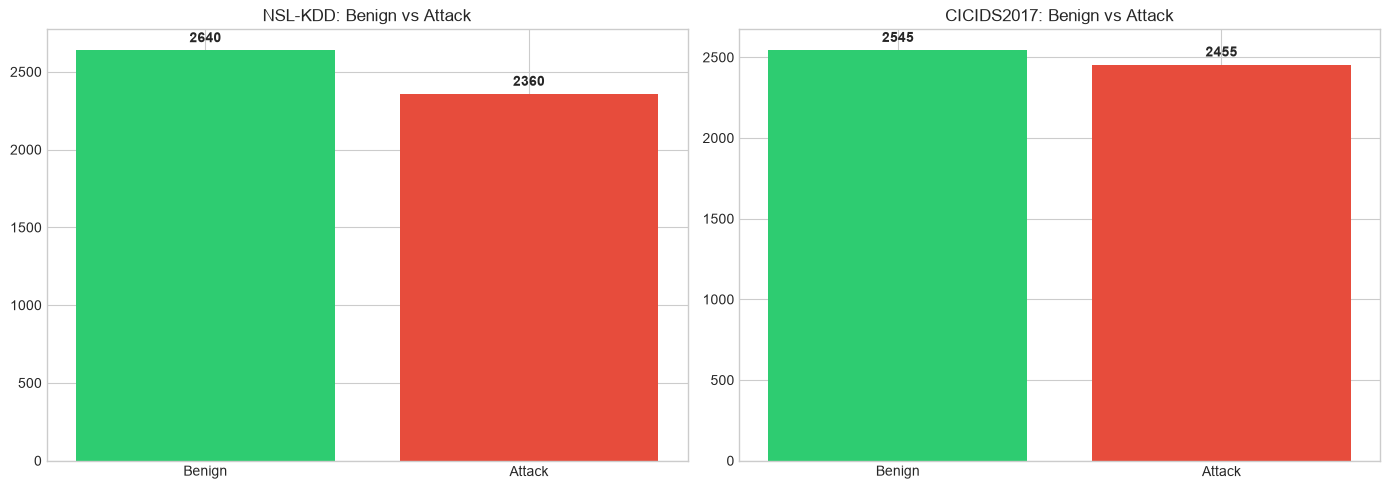

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# NSL-KDD binary distribution
nsl_counts = train_df['is_attack'].value_counts()
axes[0].bar(['Benign', 'Attack'], nsl_counts.values, color=['#2ecc71', '#e74c3c'])
axes[0].set_title('NSL-KDD: Benign vs Attack')
for i, v in enumerate(nsl_counts.values):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# CICIDS2017 binary distribution
cic_counts = cicids_df['is_attack'].value_counts()
axes[1].bar(['Benign', 'Attack'], cic_counts.values, color=['#2ecc71', '#e74c3c'])
axes[1].set_title('CICIDS2017: Benign vs Attack')
for i, v in enumerate(cic_counts.values):
    axes[1].text(i, v + 50, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/01_class_distribution.png', dpi=300, bbox_inches='tight')
plt.show()


## 3. Attack Type Distribution

Granular attack categories reveal the diversity of threats in each dataset.


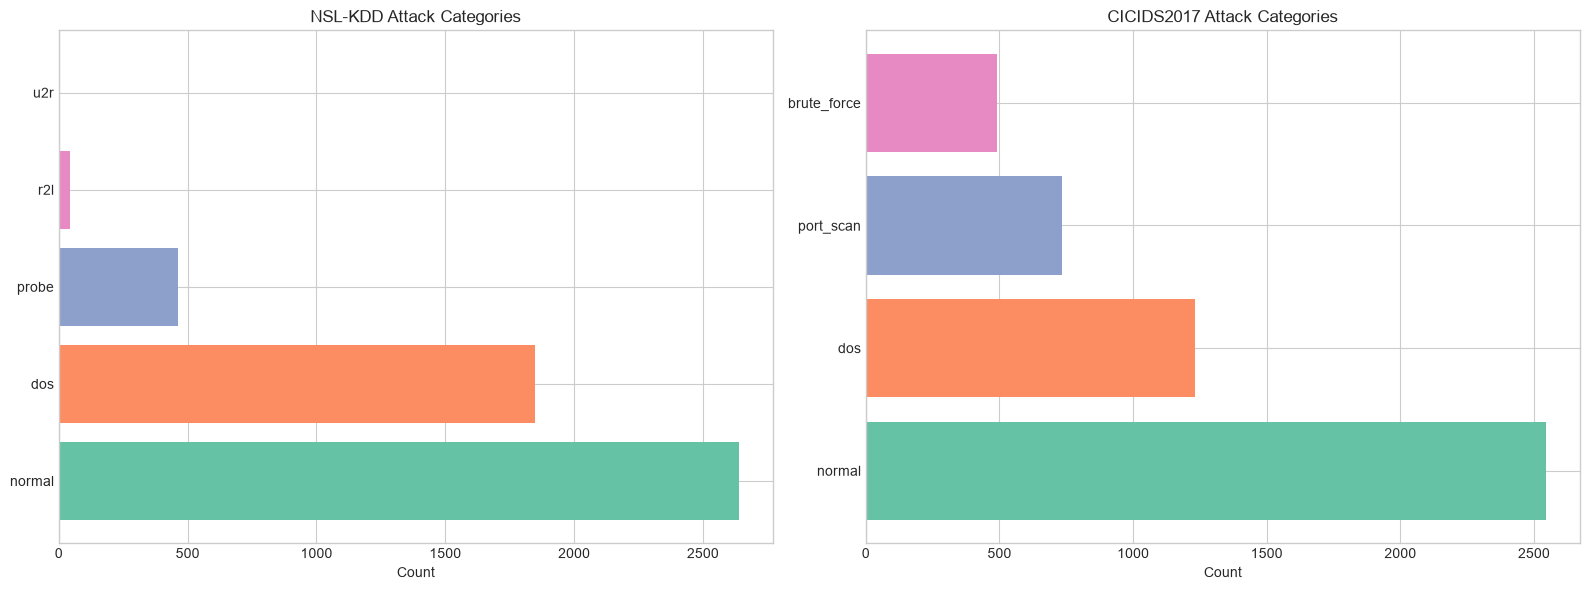

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

nsl_attacks = train_df['attack_category'].value_counts()
axes[0].barh(nsl_attacks.index, nsl_attacks.values, color=sns.color_palette('Set2', len(nsl_attacks)))
axes[0].set_title('NSL-KDD Attack Categories')
axes[0].set_xlabel('Count')

cic_attacks = cicids_df['attack_category'].value_counts()
axes[1].barh(cic_attacks.index, cic_attacks.values, color=sns.color_palette('Set2', len(cic_attacks)))
axes[1].set_title('CICIDS2017 Attack Categories')
axes[1].set_xlabel('Count')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/02_attack_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Interactive Plotly version
fig_px = px.bar(
    x=nsl_attacks.values, y=nsl_attacks.index, orientation='h',
    title='NSL-KDD Attack Distribution (Interactive)',
    labels={'x': 'Count', 'y': 'Attack Category'},
    color=nsl_attacks.values, color_continuous_scale='Viridis'
)
fig_px.write_html(f'{FIG_DIR}/02_attack_distribution_interactive.html')
fig_px.show()


## 4. Missing Values Analysis


In [6]:
processor = FeatureProcessor()
processor.identify_columns(train_df)

missing_nsl = processor.get_missing_summary(train_df)
missing_cic = processor.get_missing_summary(cicids_df)

print("NSL-KDD Missing Values:")
display(missing_nsl if len(missing_nsl) > 0 else "No missing values detected")

print("\nCICIDS2017 Missing Values:")
display(missing_cic if len(missing_cic) > 0 else "No missing values detected")


NSL-KDD Missing Values:


'No missing values detected'


CICIDS2017 Missing Values:


'No missing values detected'

## 5. Correlation Heatmaps

Highly correlated features may indicate redundancy. This informs feature selection for both network and audio pipelines.


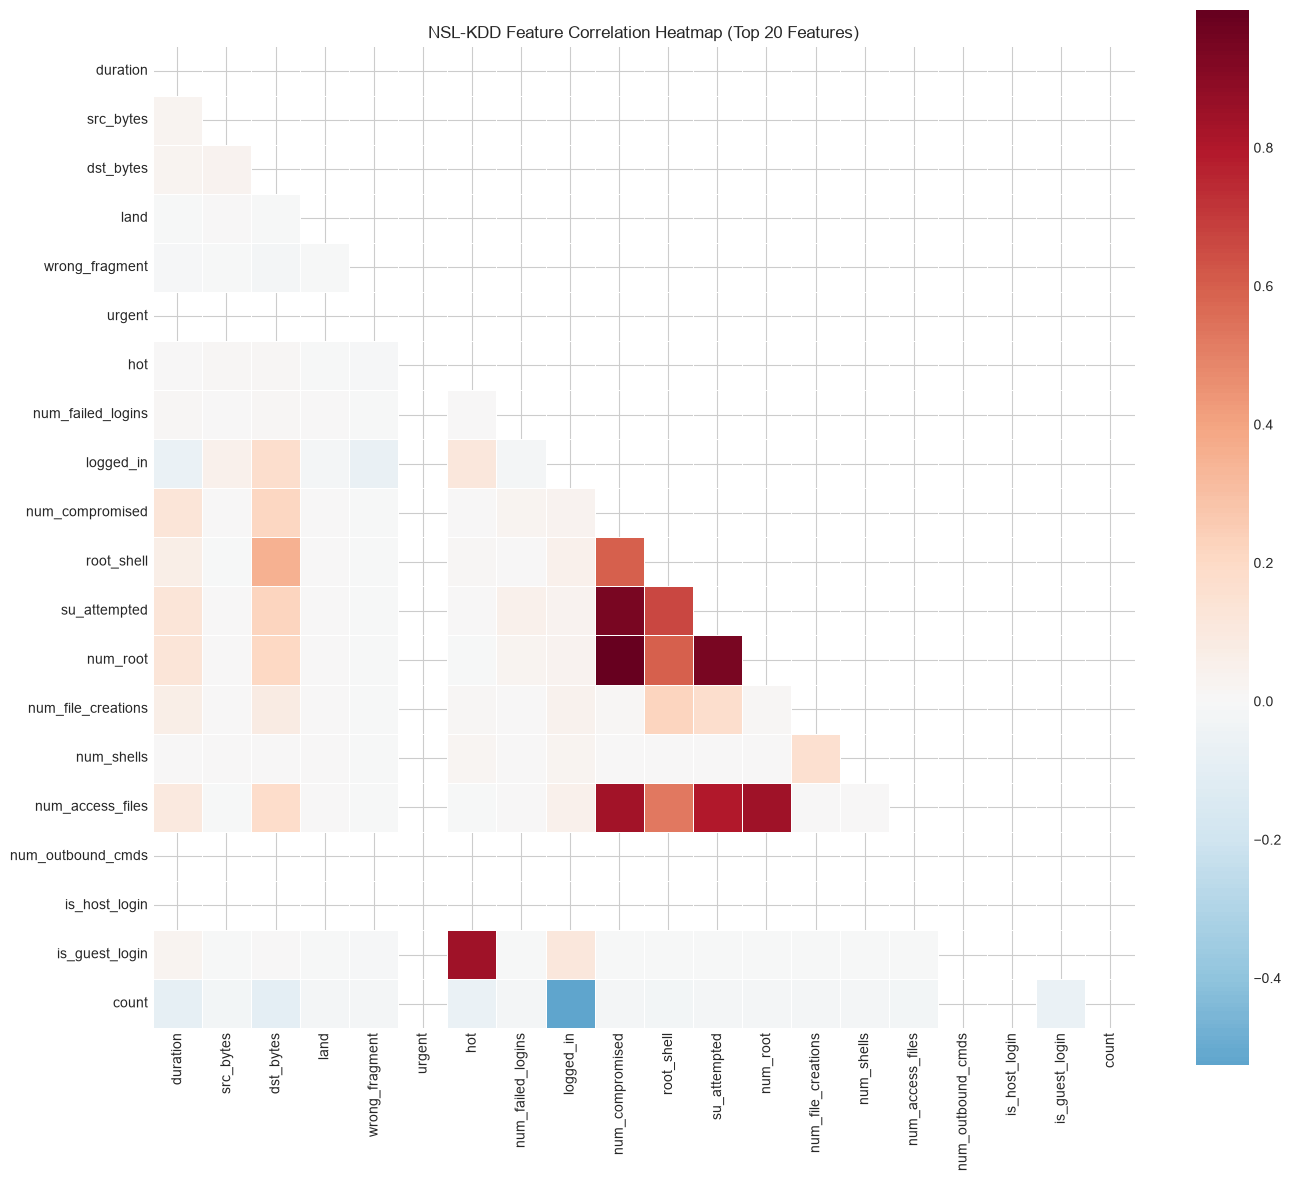

In [7]:
# Select top numeric features for readability
top_features = processor.feature_columns[:20]
corr_matrix = processor.get_correlation_matrix(train_df, top_features)

fig, ax = plt.subplots(figsize=(14, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, cmap='RdBu_r', center=0,
            annot=False, square=True, linewidths=0.5, ax=ax)
ax.set_title('NSL-KDD Feature Correlation Heatmap (Top 20 Features)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/03_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()


## 6. Feature Importance (Univariate Correlation Proxy)

Quick proxy for feature relevance before training full models.


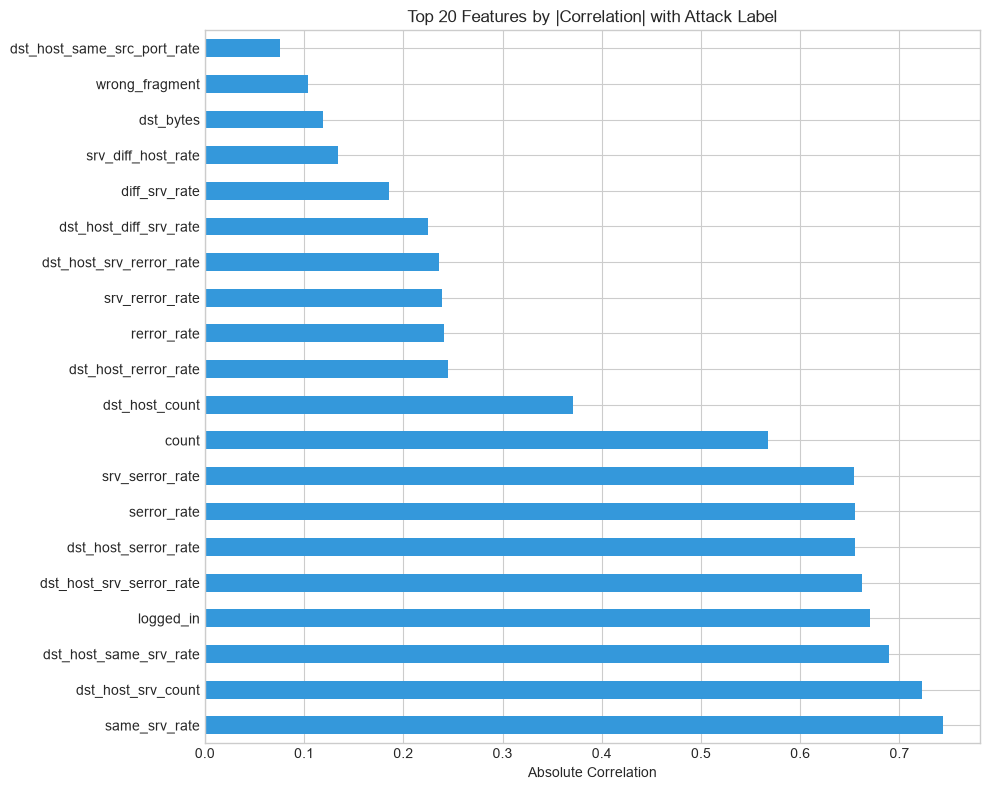

same_srv_rate               0.743965
dst_host_srv_count          0.722539
dst_host_same_srv_rate      0.689740
logged_in                   0.670780
dst_host_srv_serror_rate    0.661980
dst_host_serror_rate        0.655676
serror_rate                 0.654917
srv_serror_rate             0.654342
count                       0.567849
dst_host_count              0.370923
dst_host_rerror_rate        0.244595
rerror_rate                 0.240515
srv_rerror_rate             0.239219
dst_host_srv_rerror_rate    0.235870
dst_host_diff_srv_rate      0.225194
dtype: float64

In [8]:
importance = processor.feature_importance_proxy(train_df)
top_20 = importance.head(20)

fig, ax = plt.subplots(figsize=(10, 8))
top_20.plot(kind='barh', ax=ax, color='#3498db')
ax.set_title('Top 20 Features by |Correlation| with Attack Label')
ax.set_xlabel('Absolute Correlation')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

importance.head(15)


## 7. Outlier Analysis


Outlier percentage (z-score > 3.0): 19.64%


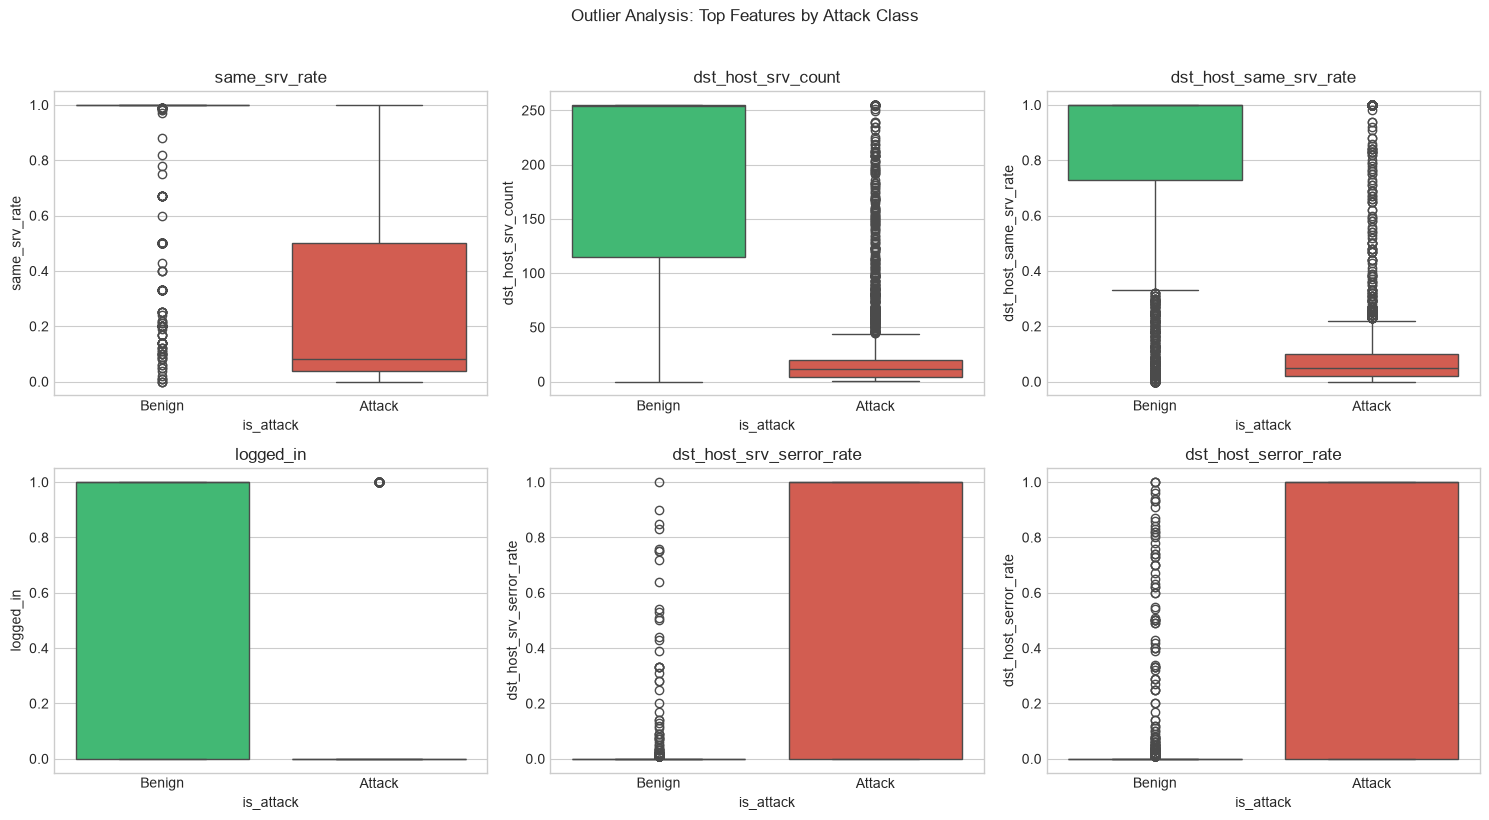

In [9]:
outlier_flags = processor.detect_outliers(train_df)
outlier_pct = outlier_flags['is_outlier'].mean() * 100
print(f"Outlier percentage (z-score > {processor.outlier_std}): {outlier_pct:.2f}%")

# Box plots for top features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, feat in zip(axes.flatten(), importance.head(6).index):
    sns.boxplot(data=train_df, x='is_attack', y=feat, ax=ax, palette=['#2ecc71', '#e74c3c'])
    ax.set_title(feat)
    ax.set_xticklabels(['Benign', 'Attack'])
plt.suptitle('Outlier Analysis: Top Features by Attack Class', y=1.02)
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_outlier_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()


## 8. Dimensionality Reduction

PCA, t-SNE, and UMAP projections reveal cluster structure in network feature space.


PCA explained variance: 0.442


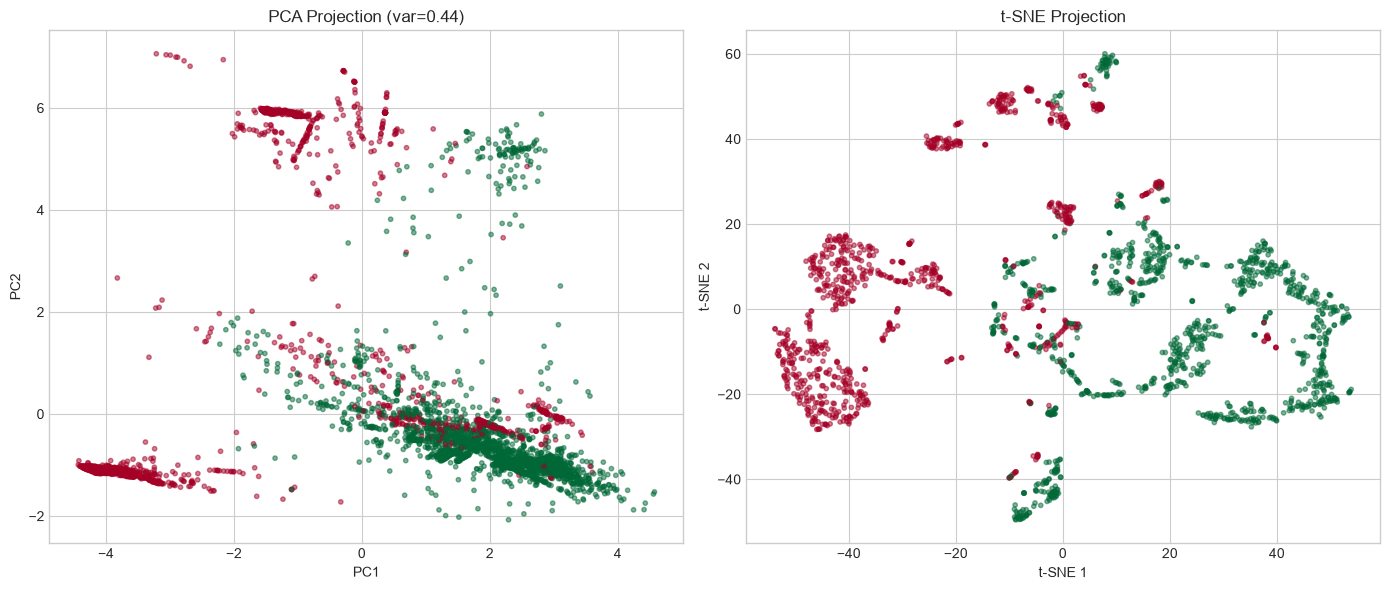

In [10]:
X, y, feat_names = processor.prepare_features(train_df, fit=True)
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"PCA explained variance: {pca.explained_variance_ratio_.sum():.3f}")

# t-SNE (subsample for speed)
tsne_sample = min(2000, len(X_scaled))
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_scaled), tsne_sample, replace=False)
X_tsne = TSNE(n_components=2, random_state=RANDOM_STATE, perplexity=30).fit_transform(X_scaled[idx])
y_tsne = y[idx]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='RdYlGn_r', alpha=0.5, s=10)
axes[0].set_title(f'PCA Projection (var={pca.explained_variance_ratio_.sum():.2f})')
axes[0].set_xlabel('PC1'); axes[0].set_ylabel('PC2')

axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_tsne, cmap='RdYlGn_r', alpha=0.5, s=10)
axes[1].set_title('t-SNE Projection')
axes[1].set_xlabel('t-SNE 1'); axes[1].set_ylabel('t-SNE 2')

plt.tight_layout()
plt.savefig(f'{FIG_DIR}/06_pca_tsne.png', dpi=300, bbox_inches='tight')
plt.show()


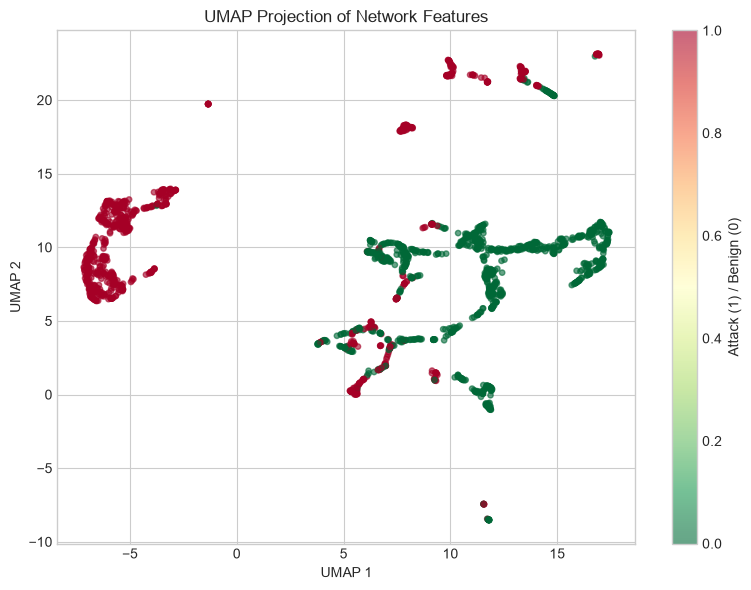

In [11]:
# UMAP projection
if HAS_UMAP:
    reducer = umap.UMAP(n_components=2, random_state=RANDOM_STATE, n_neighbors=15)
    X_umap = reducer.fit_transform(X_scaled[idx])

    fig, ax = plt.subplots(figsize=(8, 6))
    scatter = ax.scatter(X_umap[:, 0], X_umap[:, 1], c=y_tsne, cmap='RdYlGn_r', alpha=0.6, s=15)
    ax.set_title('UMAP Projection of Network Features')
    ax.set_xlabel('UMAP 1'); ax.set_ylabel('UMAP 2')
    plt.colorbar(scatter, label='Attack (1) / Benign (0)')
    plt.tight_layout()
    plt.savefig(f'{FIG_DIR}/07_umap.png', dpi=300, bbox_inches='tight')
    plt.show()
else:
    print("Install umap-learn: pip install umap-learn")


## 9. Summary

Class imbalance is present — stratified splits and F1/ROC-AUC are better evaluation metrics than raw accuracy. Several features are highly correlated, which motivates trying an alternative representation (the audio encoding in notebook 02).

**Next:** [Notebook 2 — Signal Generation](02_signal_generation.ipynb)
